# Hospital Patient Care Analytics Pipeline

## 1. Problem Understanding

A multi-specialty hospital collects patient information from different sources such as patient registration, appointment scheduling, laboratory reports, wearable health devices, and doctor consultation notes.

The main challenge is to bring all this information together and make it useful for hospital management and authorized personnel.

The hospital wants to:
- Reduce patient waiting time
- Improve appointment management
- Analyze patient-care information
- Identify high-risk patients
- Improve overall operational efficiency

## 2. Data Sources

The hospital receives data from five major sources:

1. Patient Registration
2. Appointment Scheduling
3. Laboratory Reports
4. Wearable Health Devices
5. Doctor Consultation Notes

### 2.1 Patient Registration

Contains basic patient information such as Patient ID, age, gender, and registration details.

Patient ID is used as the common identifier that connects a patient's records across the other hospital systems.

### 2.2 Appointment Scheduling

Contains appointment information such as Patient ID, Doctor, department, appointment date, scheduled time, and appointment status.

This data is used to analyze appointment availability, cancellations, waiting time, and slot utilization.

### 2.3 Laboratory Reports

Contains laboratory test information and results.

This data can be combined with other patient information for further analysis.

### 2.4 Wearable Health Devices

Wearable devices continuously generate health measurements such as heart rate and SpO2.

Since this data can arrive continuously, it can be processed using a streaming approach.

### 2.5 Doctor Consultation Notes

Contains information such as symptoms, diagnosis, prescriptions, and observations.

This information provides additional context about the patient's treatment history.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CHART_COLOR = "orange"

## 3. Load the Hospital Dataset

The hospital data is stored in a CSV file. I will load the dataset using Pandas and inspect its structure before starting the data cleaning and analysis process.

In [2]:
# Keep an unchanged copy of the source records for the Bronze layer.
# Place hospital_patient_care_dataset.csv in the same folder as this notebook.
from pathlib import Path

DATA_FILE = Path("hospital_patient_care_dataset.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Dataset not found. Place 'hospital_patient_care_dataset.csv' "
        "in the same folder as this notebook, then run the cells again."
    )

raw_df = pd.read_csv(DATA_FILE)
df = raw_df.copy()
df.head()

,patient_id,patient_name,age,gender,department,doctor,appointment_date,scheduled_time,actual_consultation_time,appointment_status,lab_test,lab_result,spo2,heart_rate,diagnosis
0,2001,Aarav,29,M,General Medicine,Dr. Verma,2026-09-21,09:40,10:13,Booked,Glucose,169.5,97,77,Pre-Diabetes
1,2002,Diya,35,M,General Medicine,Dr. Verma,2026-09-21,10:30,10:42,Completed,Cholesterol,233.2,92,102,High Cholesterol
2,2003,Rohan,76,F,General Medicine,Dr. Verma,2026-09-21,10:50,11:15,Cancelled,Cholesterol,199.7,99,94,High Cholesterol
3,2004,Ananya,24,M,Neurology,Dr. Sharma,2026-09-21,10:30,10:51,Cancelled,Glucose,180.2,98,105,Hypertension
4,2005,Vikram,68,F,Cardiology,Dr. Nair,2026-09-21,11:30,12:08,Cancelled,Glucose,179.9,93,100,Hypertension


## 4. Understanding the Dataset

The dataset contains information related to patients, appointments, doctors, laboratory results, wearable health measurements, and diagnoses.

Before processing the data, I will check the number of records, columns, data types, and missing values.

In [3]:
df.shape

(20, 15)

In [4]:
df.columns

Index(['patient_id', 'patient_name', 'age', 'gender', 'department', 'doctor',
       'appointment_date', 'scheduled_time', 'actual_consultation_time',
       'appointment_status', 'lab_test', 'lab_result', 'spo2', 'heart_rate',
       'diagnosis'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                20 non-null     int64  
 1   patient_name              20 non-null     str    
 2   age                       20 non-null     int64  
 3   gender                    20 non-null     str    
 4   department                20 non-null     str    
 5   doctor                    20 non-null     str    
 6   appointment_date          20 non-null     str    
 7   scheduled_time            20 non-null     str    
 8   actual_consultation_time  20 non-null     str    
 9   appointment_status        20 non-null     str    
 10  lab_test                  20 non-null     str    
 11  lab_result                20 non-null     float64
 12  spo2                      20 non-null     int64  
 13  heart_rate                20 non-null     int64  
 14  diagnosis              

In [6]:
df.describe()

,patient_id,age,lab_result,spo2,heart_rate
count,20.00000,20.00000,20.000000,20.000000,20.000000
mean,2010.50000,57.25000,157.255000,93.800000,99.150000
std,5.91608,17.95572,78.588224,3.518373,10.873798
min,2001.00000,24.00000,12.200000,89.000000,77.000000
25%,2005.75000,49.25000,146.825000,90.750000,93.750000
50%,2010.50000,65.00000,180.050000,93.500000,100.500000
75%,2015.25000,68.25000,210.575000,97.000000,105.500000
max,2020.00000,78.00000,233.200000,99.000000,114.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["patient_id"].duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

patient_id                  0
patient_name                0
age                         0
gender                      0
department                  0
doctor                      0
appointment_date            0
scheduled_time              0
actual_consultation_time    0
appointment_status          0
lab_test                    0
lab_result                  0
spo2                        0
heart_rate                  0
diagnosis                   0
dtype: int64

## 5. Data Cleaning and Waiting-Time Calculation

The appointment date and time columns are stored as text. I will convert them to proper datetime values so waiting time can be calculated accurately.

In [10]:
df["appointment_date"] = pd.to_datetime(df["appointment_date"])

df["scheduled_time"] = pd.to_datetime(
    df["appointment_date"].dt.strftime("%Y-%m-%d")
    + " " + df["scheduled_time"]
)

df["actual_consultation_time"] = pd.to_datetime(
    df["appointment_date"].dt.strftime("%Y-%m-%d")
    + " " + df["actual_consultation_time"]
)

df.dtypes

patient_id                           int64
patient_name                           str
age                                  int64
gender                                 str
department                             str
doctor                                 str
appointment_date            datetime64[us]
scheduled_time              datetime64[us]
actual_consultation_time    datetime64[us]
appointment_status                     str
lab_test                               str
lab_result                         float64
spo2                                 int64
heart_rate                           int64
diagnosis                              str
dtype: object

In [11]:
df["waiting_time_minutes"] = (
    df["actual_consultation_time"] -
    df["scheduled_time"]
).dt.total_seconds() / 60

df[[
    "patient_id",
    "scheduled_time",
    "actual_consultation_time",
    "waiting_time_minutes"
]].head()

,patient_id,scheduled_time,actual_consultation_time,waiting_time_minutes
0,2001,2026-09-21 09:40:00,2026-09-21 10:13:00,33.0
1,2002,2026-09-21 10:30:00,2026-09-21 10:42:00,12.0
2,2003,2026-09-21 10:50:00,2026-09-21 11:15:00,25.0
3,2004,2026-09-21 10:30:00,2026-09-21 10:51:00,21.0
4,2005,2026-09-21 11:30:00,2026-09-21 12:08:00,38.0


## 6. Appointment Analysis

The appointment data can be used to understand how appointments are distributed across different statuses and departments.

In [12]:
appointment_counts = df["appointment_status"].value_counts()
appointment_counts

appointment_status
Completed              12
Booked                  4
Cancelled               3
Emergency Cancelled     1
Name: count, dtype: int64

In [13]:
df["department"].value_counts()

department
General Medicine    7
Cardiology          7
Neurology           6
Name: count, dtype: int64

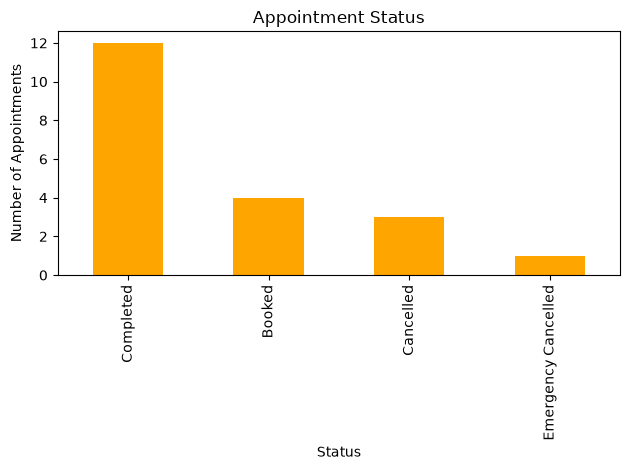

In [14]:
appointment_counts.plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Appointment Status")
plt.xlabel("Status")
plt.ylabel("Number of Appointments")

plt.tight_layout()
plt.show()

### Insight

The appointment status analysis shows the number of completed, booked, cancelled, and emergency-cancelled appointments. This helps the hospital understand appointment utilization and cancellation patterns.

In [15]:
df["waiting_time_minutes"].mean().round(2)

np.float64(38.25)

In [16]:
dept_wait_time = df.groupby("department")["waiting_time_minutes"].mean().round(2)
dept_wait_time

department
Cardiology          40.14
General Medicine    35.14
Neurology           39.67
Name: waiting_time_minutes, dtype: float64

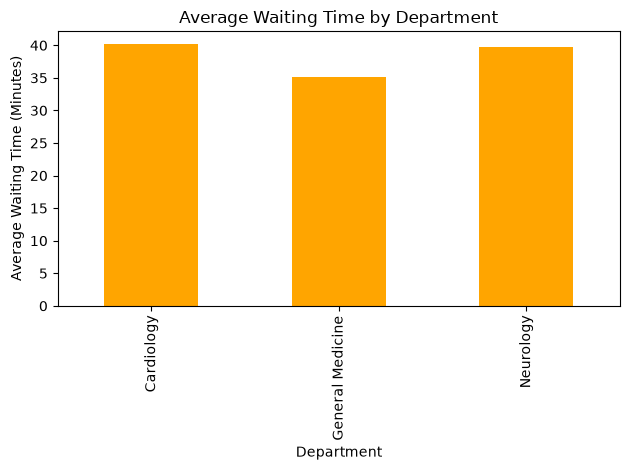

In [17]:
dept_wait_time.plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Average Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Average Waiting Time (Minutes)")

plt.tight_layout()
plt.show()

### Insight

The department-wise waiting-time analysis helps identify departments where patients experience longer waiting periods. This information can help hospital management understand where operational improvements may be required.

## 7. Laboratory Analysis

Laboratory results can be analyzed to understand the distribution of test results and identify records that may require further attention.

In [18]:
df.groupby("lab_test")["lab_result"].mean().round(2)

lab_test
Blood Test      13.80
Cholesterol    216.50
Glucose        163.06
Name: lab_result, dtype: float64

In [19]:
df["lab_test"].value_counts()

lab_test
Cholesterol    9
Glucose        7
Blood Test     4
Name: count, dtype: int64

In [20]:
df[[
    "patient_id",
    "lab_test",
    "lab_result",
    "diagnosis"
]]

,patient_id,lab_test,lab_result,diagnosis
0,2001,Glucose,169.5,Pre-Diabetes
1,2002,Cholesterol,233.2,High Cholesterol
2,2003,Cholesterol,199.7,High Cholesterol
3,2004,Glucose,180.2,Hypertension
4,2005,Glucose,179.9,Hypertension
5,2006,Blood Test,14.2,Migraine
6,2007,Cholesterol,194.6,Hypertension
7,2008,Cholesterol,229.2,Routine Checkup
8,2009,Cholesterol,208.1,Routine Checkup
9,2010,Blood Test,14.5,Anemia


## 8. Wearable Health Data Analysis

Wearable devices continuously generate health measurements. In this dataset, heart rate and SpO2 are used as examples of wearable measurements.

In a real system, this type of data could be processed using a streaming pipeline.

In [21]:
df[[
    "patient_id",
    "heart_rate",
    "spo2"
]].head()

,patient_id,heart_rate,spo2
0,2001,77,97
1,2002,102,92
2,2003,94,99
3,2004,105,98
4,2005,100,93


In [22]:
df["heart_rate"].describe()

count     20.000000
mean      99.150000
std       10.873798
min       77.000000
25%       93.750000
50%      100.500000
75%      105.500000
max      114.000000
Name: heart_rate, dtype: float64

In [23]:
df["spo2"].describe()

count    20.000000
mean     93.800000
std       3.518373
min      89.000000
25%      90.750000
50%      93.500000
75%      97.000000
max      99.000000
Name: spo2, dtype: float64

In [24]:
elevated_heart_rate = df[df["heart_rate"] > 100]

elevated_heart_rate[[
    "patient_id",
    "heart_rate",
    "spo2"
]]

,patient_id,heart_rate,spo2
1,2002,102,92
3,2004,105,98
5,2006,114,89
9,2010,113,97
10,2011,109,90
12,2013,107,93
14,2015,114,99
15,2016,105,97
16,2017,104,94
19,2020,101,94


In [25]:
low_oxygen = df[df["spo2"] < 95]

low_oxygen[[
    "patient_id",
    "heart_rate",
    "spo2"
]]

,patient_id,heart_rate,spo2
1,2002,102,92
4,2005,100,93
5,2006,114,89
6,2007,80,91
8,2009,93,89
10,2011,109,90
11,2012,100,90
12,2013,107,93
16,2017,104,94
17,2018,88,89


## 9. High-Risk Patient Identification

The integrated patient data can be used as input for identifying patients who may require additional attention.

For this demonstration, a simple rule-based risk score is created using age, heart rate, and SpO2. In a real hospital environment, a properly validated machine-learning model would be required.

In [26]:
df["risk_score"] = 0

df.loc[df["age"] >= 60, "risk_score"] += 1
df.loc[df["heart_rate"] > 100, "risk_score"] += 1
df.loc[df["spo2"] < 95, "risk_score"] += 1

In [27]:
risk_bins = [-1, 0, 1, 10]
risk_labels = ["Low", "Medium", "High"]

df["risk_level"] = pd.cut(
    df["risk_score"],
    bins=risk_bins,
    labels=risk_labels
)

df[[
    "patient_id",
    "age",
    "heart_rate",
    "spo2",
    "risk_score",
    "risk_level"
]]

,patient_id,age,heart_rate,spo2,risk_score,risk_level
0,2001,29,77,97,0,Low
1,2002,35,102,92,2,High
2,2003,76,94,99,1,Medium
3,2004,24,105,98,1,Medium
4,2005,68,100,93,2,High
5,2006,68,114,89,3,High
6,2007,76,80,91,2,High
7,2008,55,99,98,0,Low
8,2009,54,93,89,1,Medium
9,2010,69,113,97,2,High


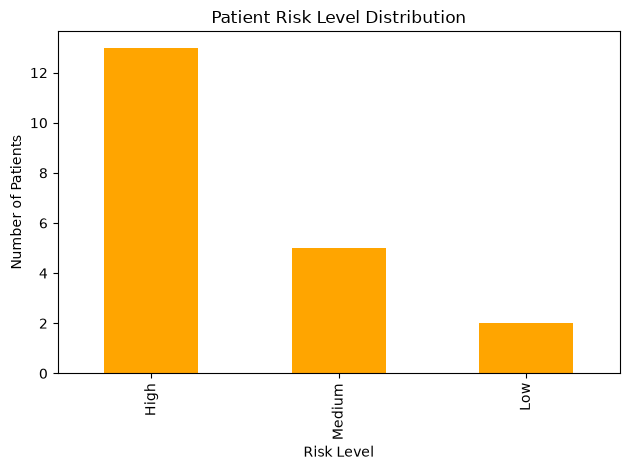

In [28]:
df["risk_level"].value_counts().plot(
    kind="bar",
    color=CHART_COLOR
)

plt.title("Patient Risk Level Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

### Insight

The risk-level distribution gives hospital staff a quick view of how many patients currently fall into the low, medium, and high-risk categories, so attention can be prioritized accordingly.

## 10. Emergency Cancellation Analysis

Emergency cancellation is treated as an appointment event. When an emergency cancellation occurs, the affected appointment must be identified and the patient should be informed.

In a real application, the workflow would update the slot status, notify the affected patient, and provide alternative slots for rescheduling.

In [29]:
df[df["appointment_status"] == "Emergency Cancelled"]

,patient_id,patient_name,age,gender,department,doctor,appointment_date,scheduled_time,actual_consultation_time,appointment_status,lab_test,lab_result,spo2,heart_rate,diagnosis,waiting_time_minutes,risk_score,risk_level
11,2012,Priya,28,M,General Medicine,Dr. Verma,2026-09-21,2026-09-21 13:40:00,2026-09-21 14:16:00,Emergency Cancelled,Cholesterol,231.8,90,100,Hypertension,36.0,1,Medium


In [30]:
df["doctor"].value_counts()

doctor
Dr. Verma     7
Dr. Nair      7
Dr. Sharma    6
Name: count, dtype: int64

In [31]:
df.groupby("doctor")["appointment_status"].count()

doctor
Dr. Nair      7
Dr. Sharma    6
Dr. Verma     7
Name: appointment_status, dtype: int64

## 11. Summary Statistics

In [32]:
total_patients = df["patient_id"].nunique()
total_appointments = len(df)

completed = (df["appointment_status"] == "Completed").sum()

cancelled = df["appointment_status"].isin(
    ["Cancelled", "Emergency Cancelled"]
).sum()

average_waiting_time = df["waiting_time_minutes"].mean()

high_risk_patients = (df["risk_level"] == "High").sum()

print("Total Patients:", total_patients)
print("Total Appointments:", total_appointments)
print("Completed Appointments:", completed)
print("Cancelled Appointments:", cancelled)
print("Average Waiting Time:", round(average_waiting_time, 2), "minutes")
print("High-Risk Patients:", high_risk_patients)

Total Patients: 20
Total Appointments: 20
Completed Appointments: 12
Cancelled Appointments: 4
Average Waiting Time: 38.25 minutes
High-Risk Patients: 13


## 12. Initial Analysis Summary

The source dataset was loaded, inspected, cleaned, transformed, and analyzed. The initial analysis covered:

- Appointment status and department-wise waiting time
- Laboratory results
- Wearable heart-rate and SpO2 measurements
- Emergency cancellations
- Rule-based patient review indicators
- Summary statistics and operational KPIs

The following sections extend this analysis into a learning data-engineering workflow with Bronze, Silver, and Gold layers, SQL analytics, clinical-review support, export, and documented production safeguards.

## 13. Data Pipeline Architecture: Extract → Bronze → Silver → Gold

This section demonstrates a small, local medallion-style pipeline. It is a learning prototype, not a live hospital integration.

- **Extract:** Read the supplied CSV source into `raw_df`.
- **Bronze:** Preserve an unchanged copy of the source records and attach ingestion metadata.
- **Silver:** Standardize data types, remove exact duplicate rows, and validate required fields.
- **Gold:** Build analysis-ready patient/appointment and department-level tables.

The pipeline uses the existing dataset and does not fabricate missing clinical fields. If consultation notes are not present in the CSV, they remain an identified source-system requirement rather than being invented.

In [33]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import time

# EXTRACT: raw_df was loaded from the CSV in Section 3.
source_row_count = len(raw_df)
ingestion_timestamp = datetime.now(timezone.utc).isoformat()

# BRONZE: retain the original source values without cleaning or overwriting them.
bronze_df = raw_df.copy(deep=True)
bronze_df["_source_file"] = DATA_FILE.name
bronze_df["_ingested_at_utc"] = ingestion_timestamp
bronze_df["_source_row_number"] = np.arange(1, len(bronze_df) + 1)

print("Bronze rows:", len(bronze_df))
print("Source file:", DATA_FILE.name)
print("Ingested at (UTC):", ingestion_timestamp)
bronze_df.head()

Bronze rows: 20
Source file: hospital_patient_care_dataset.csv
Ingested at (UTC): 2026-11-09T07:00:18.681577+00:00


,patient_id,patient_name,age,gender,department,doctor,appointment_date,scheduled_time,actual_consultation_time,appointment_status,lab_test,lab_result,spo2,heart_rate,diagnosis,_source_file,_ingested_at_utc,_source_row_number
0,2001,Aarav,29,M,General Medicine,Dr. Verma,2026-09-21,09:40,10:13,Booked,Glucose,169.5,97,77,Pre-Diabetes,hospital_patient_care_dataset.csv,2026-11-09T07:00:18.681577+00:00,1
1,2002,Diya,35,M,General Medicine,Dr. Verma,2026-09-21,10:30,10:42,Completed,Cholesterol,233.2,92,102,High Cholesterol,hospital_patient_care_dataset.csv,2026-11-09T07:00:18.681577+00:00,2
2,2003,Rohan,76,F,General Medicine,Dr. Verma,2026-09-21,10:50,11:15,Cancelled,Cholesterol,199.7,99,94,High Cholesterol,hospital_patient_care_dataset.csv,2026-11-09T07:00:18.681577+00:00,3
3,2004,Ananya,24,M,Neurology,Dr. Sharma,2026-09-21,10:30,10:51,Cancelled,Glucose,180.2,98,105,Hypertension,hospital_patient_care_dataset.csv,2026-11-09T07:00:18.681577+00:00,4
4,2005,Vikram,68,F,Cardiology,Dr. Nair,2026-09-21,11:30,12:08,Cancelled,Glucose,179.9,93,100,Hypertension,hospital_patient_care_dataset.csv,2026-11-09T07:00:18.681577+00:00,5


### 13.1 Silver layer: cleaned and validated records

The Silver layer starts from the cleaned `df` created in Sections 5–9. It standardizes key fields, checks required columns, removes exact duplicate rows, and records basic quality metrics. It deliberately retains records with missing values for review instead of silently inventing values.

In [34]:
# SILVER: create a separate, analysis-ready copy.
silver_df = df.copy(deep=True)

required_columns = [
    "patient_id", "age", "appointment_status", "department",
    "scheduled_time", "actual_consultation_time", "waiting_time_minutes",
    "lab_test", "lab_result", "heart_rate", "spo2"
]
missing_required = [c for c in required_columns if c not in silver_df.columns]
if missing_required:
    raise ValueError(f"Required dataset columns are missing: {missing_required}")

# Standardize text fields and numeric measurements.
for col in ["patient_id", "appointment_status", "department", "lab_test"]:
    silver_df[col] = silver_df[col].astype("string").str.strip()
for col in ["age", "waiting_time_minutes", "lab_result", "heart_rate", "spo2"]:
    silver_df[col] = pd.to_numeric(silver_df[col], errors="coerce")

before_dedup = len(silver_df)
silver_df = silver_df.drop_duplicates().copy()
removed_duplicates = before_dedup - len(silver_df)

quality_report = pd.DataFrame({
    "metric": ["rows_in_bronze", "rows_in_silver", "exact_duplicates_removed", "missing_patient_id", "missing_department"],
    "value": [len(bronze_df), len(silver_df), removed_duplicates,
              int(silver_df["patient_id"].isna().sum()), int(silver_df["department"].isna().sum())]
})
quality_report

,metric,value
0,rows_in_bronze,20
1,rows_in_silver,20
2,exact_duplicates_removed,0
3,missing_patient_id,0
4,missing_department,0


### 13.2 Gold layer: curated analytical tables

Gold tables contain aggregated measures intended for reporting. Patient identifiers are not needed in department-level reporting, so the aggregate table omits them. Patient-level review output is kept separately and should only be exposed to authorized clinical users.

In [35]:
# GOLD: department-level appointment performance.
valid_waits = silver_df.dropna(subset=["department", "waiting_time_minutes"])
gold_department_kpis = (
    valid_waits.groupby("department", dropna=False)
    .agg(
        appointment_count=("patient_id", "size"),
        average_waiting_time_minutes=("waiting_time_minutes", "mean"),
        median_waiting_time_minutes=("waiting_time_minutes", "median")
    )
    .reset_index()
)

# GOLD: appointment status summary.
gold_appointment_status = (
    silver_df["appointment_status"].value_counts(dropna=False)
    .rename_axis("appointment_status").reset_index(name="appointment_count")
)

gold_department_kpis.head(), gold_appointment_status

(         department  appointment_count  average_waiting_time_minutes  \
 0        Cardiology                  7                     40.142857   
 1  General Medicine                  7                     35.142857   
 2         Neurology                  6                     39.666667   
 
    median_waiting_time_minutes  
 0                         38.0  
 1                         33.0  
 2                         44.0  ,
     appointment_status  appointment_count
 0            Completed                 12
 1               Booked                  4
 2            Cancelled                  3
 3  Emergency Cancelled                  1)

## 14. SQL Analytics

The Gold tables are loaded into an in-memory SQLite database to demonstrate SQL-based reporting. This database exists only for the current notebook session; it is not a secured production database.

In [36]:
import sqlite3

sql_connection = sqlite3.connect(":memory:")
gold_department_kpis.to_sql("gold_department_kpis", sql_connection, if_exists="replace", index=False)
gold_appointment_status.to_sql("gold_appointment_status", sql_connection, if_exists="replace", index=False)

sql_department_report = pd.read_sql_query("""
    SELECT department,
           appointment_count,
           ROUND(average_waiting_time_minutes, 2) AS average_waiting_time_minutes,
           ROUND(median_waiting_time_minutes, 2) AS median_waiting_time_minutes
    FROM gold_department_kpis
    ORDER BY average_waiting_time_minutes DESC
""", sql_connection)

sql_status_report = pd.read_sql_query("""
    SELECT appointment_status, appointment_count
    FROM gold_appointment_status
    ORDER BY appointment_count DESC
""", sql_connection)

print("Department performance from SQL:")
display(sql_department_report)
print("Appointment status from SQL:")
display(sql_status_report)

Department performance from SQL:


,department,appointment_count,average_waiting_time_minutes,median_waiting_time_minutes
0,Cardiology,7,40.14,38.0
1,Neurology,6,39.67,44.0
2,General Medicine,7,35.14,33.0


Appointment status from SQL:


,appointment_status,appointment_count
0,Completed,12
1,Booked,4
2,Cancelled,3
3,Emergency Cancelled,1


## 15. Clinical Review Support (not automated diagnosis)

The following flags reproduce the simple educational rules from Section 9. They are **not clinical thresholds, diagnoses, or treatment recommendations**. The output is only a queue for review by qualified healthcare professionals. A clinician must interpret measurements in context and determine any action.

In [37]:
clinical_review_df = silver_df.copy()
clinical_review_df["review_reasons"] = ""

if "age" in clinical_review_df.columns:
    clinical_review_df.loc[clinical_review_df["age"] >= 60, "review_reasons"] += "Age rule; "
if "heart_rate" in clinical_review_df.columns:
    clinical_review_df.loc[clinical_review_df["heart_rate"] > 100, "review_reasons"] += "Heart-rate rule; "
if "spo2" in clinical_review_df.columns:
    clinical_review_df.loc[clinical_review_df["spo2"] < 95, "review_reasons"] += "SpO2 rule; "

clinical_review_df["requires_clinical_review"] = clinical_review_df["review_reasons"].ne("")
review_queue = clinical_review_df.loc[
    clinical_review_df["requires_clinical_review"],
    ["patient_id", "age", "heart_rate", "spo2", "review_reasons"]
].copy()

print("Records flagged for professional review:", len(review_queue))
review_queue.head(10)

Records flagged for professional review: 18


,patient_id,age,heart_rate,spo2,review_reasons
1,2002,35,102,92,Heart-rate rule; SpO2 rule;
2,2003,76,94,99,Age rule;
3,2004,24,105,98,Heart-rate rule;
4,2005,68,100,93,Age rule; SpO2 rule;
5,2006,68,114,89,Age rule; Heart-rate rule; SpO2 rule;
6,2007,76,80,91,Age rule; SpO2 rule;
8,2009,54,93,89,SpO2 rule;
9,2010,69,113,97,Age rule; Heart-rate rule;
10,2011,30,109,90,Heart-rate rule; SpO2 rule;
11,2012,28,100,90,SpO2 rule;


## 16. KPI Dashboard and Visualizations

This section consolidates operational KPIs and provides a compact dashboard. KPIs are descriptive summaries of the supplied sample data, not measures of clinical quality.

In [38]:
status = silver_df["appointment_status"].astype("string").str.lower()
total_appointments_gold = int(len(silver_df))
completed_appointments_gold = int(status.eq("completed").sum())
cancelled_appointments_gold = int(status.isin(["cancelled", "emergency cancelled"]).sum())
completion_rate = (completed_appointments_gold / total_appointments_gold * 100) if total_appointments_gold else np.nan
cancellation_rate = (cancelled_appointments_gold / total_appointments_gold * 100) if total_appointments_gold else np.nan
avg_wait_gold = silver_df["waiting_time_minutes"].mean()
unique_patients_gold = int(silver_df["patient_id"].nunique())
review_count_gold = int(clinical_review_df["requires_clinical_review"].sum())

gold_kpi_summary = pd.DataFrame({
    "KPI": ["Unique patients", "Total appointments", "Completed appointments", "Cancelled appointments",
            "Completion rate (%)", "Cancellation rate (%)", "Average waiting time (minutes)",
            "Records flagged for clinical review"],
    "Value": [unique_patients_gold, total_appointments_gold, completed_appointments_gold,
              cancelled_appointments_gold, round(completion_rate, 2), round(cancellation_rate, 2),
              round(avg_wait_gold, 2) if pd.notna(avg_wait_gold) else np.nan, review_count_gold]
})
gold_kpi_summary

,KPI,Value
0,Unique patients,20.00
1,Total appointments,20.00
2,Completed appointments,12.00
3,Cancelled appointments,4.00
4,Completion rate (%),60.00
5,Cancellation rate (%),20.00
6,Average waiting time (minutes),38.25
7,Records flagged for clinical review,18.00


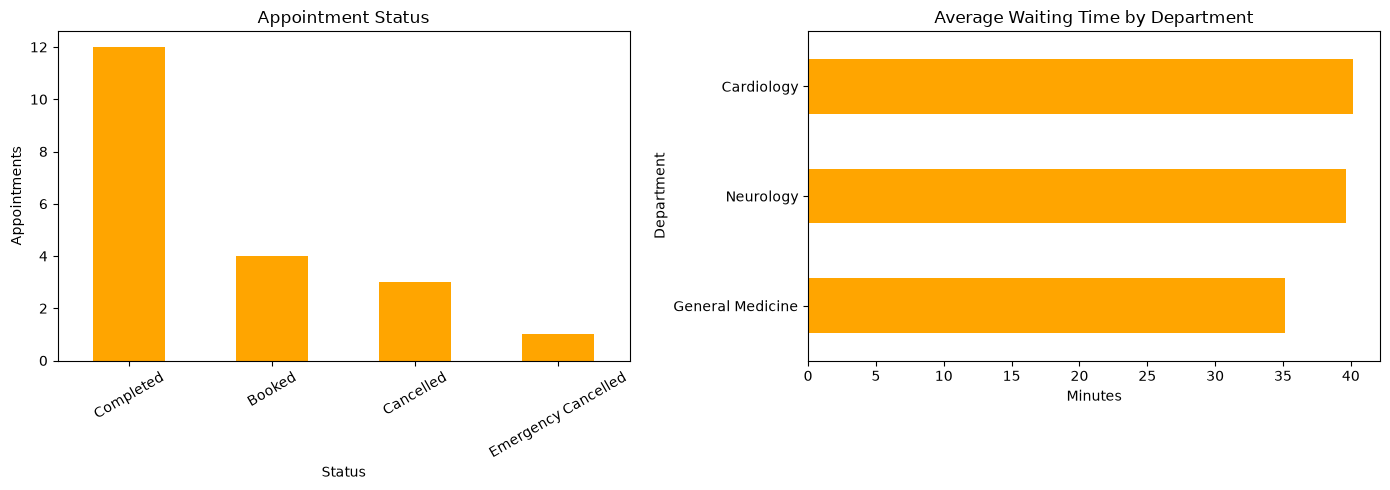

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gold_appointment_status.set_index("appointment_status")["appointment_count"].plot(
    kind="bar", ax=axes[0], color=CHART_COLOR, title="Appointment Status"
)
axes[0].set_xlabel("Status")
axes[0].set_ylabel("Appointments")
axes[0].tick_params(axis="x", rotation=30)

gold_department_kpis.sort_values("average_waiting_time_minutes").plot(
    x="department", y="average_waiting_time_minutes", kind="barh", ax=axes[1],
    color=CHART_COLOR, legend=False, title="Average Waiting Time by Department"
)
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("Department")
plt.tight_layout()
plt.show()

## 17. Export Functionality

Export the curated Gold reports and the restricted clinical-review queue as separate CSV files. In a real deployment, the review queue must be stored in an access-controlled location; do not distribute patient-level data in general-purpose reports.

In [40]:
EXPORT_DIR = Path("hospital_analytics_exports")
EXPORT_DIR.mkdir(exist_ok=True)

gold_department_kpis.to_csv(EXPORT_DIR / "gold_department_kpis.csv", index=False)
gold_appointment_status.to_csv(EXPORT_DIR / "gold_appointment_status.csv", index=False)
gold_kpi_summary.to_csv(EXPORT_DIR / "gold_kpi_summary.csv", index=False)
# Restricted output: use only in an approved, access-controlled environment.
review_queue.to_csv(EXPORT_DIR / "restricted_clinical_review_queue.csv", index=False)

print("Exported files:")
for exported_file in sorted(EXPORT_DIR.glob("*.csv")):
    print("-", exported_file)

Exported files:
- hospital_analytics_exports\gold_appointment_status.csv
- hospital_analytics_exports\gold_department_kpis.csv
- hospital_analytics_exports\gold_kpi_summary.csv
- hospital_analytics_exports\restricted_clinical_review_queue.csv


## 18. Security, Privacy, and Production Considerations

For a real hospital deployment, the following safeguards are required. The notebook documents these controls but does **not** implement production-grade security or governance.

- **Role-based access control (RBAC):** Restrict identifiable clinical information to authorized roles such as clinicians, analysts, and administrators. Apply least-privilege permissions.
- **Data minimization:** Expose only fields required for each analytical purpose. Prefer aggregated Gold reports for operational users.
- **Encryption:** Encrypt data at rest and in transit using organization-approved key management and transport security. No encryption is configured by this notebook.
- **Monitoring and auditing:** Record pipeline runs, failures, and data-access events in a protected audit system. Avoid writing sensitive clinical values into logs.
- **Data lineage:** Preserve source file, ingestion time, transformation version, and output references from source through Bronze, Silver, and Gold.
- **Reliability:** Use a production orchestrator for scheduling, dependency management, retries, idempotency, and failure alerts.
- **Governance:** Obtain clinical, legal, privacy, and information-security approval before operational use. Apply retention and deletion policies.
- **Clinical safety:** Validate any clinical rules with qualified professionals. The sample thresholds in this notebook are illustrative only.

### 18.1 Demonstration lineage and audit metadata

The following metadata is a lightweight traceability example, not a secure audit log. A hash can help detect changes to a serialized artifact, but it does not encrypt data or prove who accessed it.

In [41]:
# Lightweight lineage record for this notebook run.
lineage_record = {
    "source_file": DATA_FILE.name,
    "source_rows": int(len(raw_df)),
    "bronze_rows": int(len(bronze_df)),
    "silver_rows": int(len(silver_df)),
    "gold_department_rows": int(len(gold_department_kpis)),
    "ingested_at_utc": ingestion_timestamp,
    "pipeline_stages": ["Extract", "Bronze", "Silver", "Gold", "SQL Analytics", "Export"],
    "note": "Learning prototype; no production access control or encryption"
}
lineage_json = json.dumps(lineage_record, sort_keys=True, indent=2)
lineage_hash = hashlib.sha256(lineage_json.encode("utf-8")).hexdigest()

with open(EXPORT_DIR / "pipeline_lineage.json", "w", encoding="utf-8") as f:
    f.write(lineage_json)

print(lineage_json)
print("Lineage SHA-256:", lineage_hash)

{
  "bronze_rows": 20,
  "gold_department_rows": 3,
  "ingested_at_utc": "2026-11-09T07:00:18.681577+00:00",
  "note": "Learning prototype; no production access control or encryption",
  "pipeline_stages": [
    "Extract",
    "Bronze",
    "Silver",
    "Gold",
    "SQL Analytics",
    "Export"
  ],
  "silver_rows": 20,
  "source_file": "hospital_patient_care_dataset.csv",
  "source_rows": 20
}
Lineage SHA-256: bd0e2729a92d3a99e23b0156d614d92d98202380275ed489ba609c2e064faa9c


### 18.2 RBAC policy example (documentation only)

This table describes an example permission design. It does not enforce permissions inside Jupyter or the exported CSV files.

In [42]:
rbac_policy_example = pd.DataFrame([
    {"role": "Clinician", "patient_level_data": "Approved care-team access", "aggregated_reports": "Yes", "administer_users": "No"},
    {"role": "Data Analyst", "patient_level_data": "De-identified/minimized only", "aggregated_reports": "Yes", "administer_users": "No"},
    {"role": "Hospital Administrator", "patient_level_data": "Only when explicitly authorized", "aggregated_reports": "Yes", "administer_users": "Limited"},
    {"role": "System Administrator", "patient_level_data": "No routine clinical access", "aggregated_reports": "Operational need only", "administer_users": "Yes"}
])
rbac_policy_example

,role,patient_level_data,aggregated_reports,administer_users
0,Clinician,Approved care-team access,Yes,No
1,Data Analyst,De-identified/minimized only,Yes,No
2,Hospital Administrator,Only when explicitly authorized,Yes,Limited
3,System Administrator,No routine clinical access,Operational need only,Yes


## 19. Conclusion

This notebook demonstrates an end-to-end **learning prototype** for hospital patient-care analytics:

**Extract → Bronze → Silver → Gold → SQL Analytics → Clinical Review Support → KPIs → Visualizations → Export**

It brings together the available patient registration, appointment, laboratory, and wearable measurements in the supplied dataset, then transforms the data into operational summaries and a separate review queue. Doctor consultation notes are described as a hospital data source, but they are only analyzed if the supplied dataset actually contains suitable consultation fields; no missing notes are fabricated.

The Bronze layer preserves source records, the Silver layer standardizes and validates data, and the Gold layer provides curated analytical tables. SQL queries demonstrate reporting over Gold data, while KPI tables and Matplotlib charts summarize operational patterns. CSV and lineage metadata exports make the outputs reusable.

All sample records must be treated as fictional or appropriately de-identified for this educational exercise. The rule-based review flags are not diagnoses and must be assessed by authorized healthcare professionals. The notebook is **not production-ready**: RBAC, encryption, secure audit infrastructure, orchestration, automated alerts, and clinical/legal governance must be implemented and approved before any real hospital deployment.